# Fetching the Dataset

In [1]:
! gdown <PRIVATE_DATASET_ID>

Downloading...
From (original): https://drive.google.com/uc?id=<PRIVATE_DATASET_ID>
From (redirected): https://drive.google.com/uc?id=<PRIVATE_DATASET_ID>&confirm=t&uuid=<redacted>
To: /content/ai_vs_real_img_dataset.zip
100% 3.61G/3.61G [00:40<00:00, 88.3MB/s]


In [2]:
!unzip -q *.zip -d Dataset/

# Importing Dependencies

In [3]:
!pip install tensorflow -q

In [4]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing import image_dataset_from_directory
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, recall_score, precision_score, confusion_matrix, roc_curve, auc
import seaborn as sns

# Constants

In [5]:
BATCH_SIZE = 256 #For GPU 16
IMAGE_SIZE = 256
CHANNELS = 3
EPOCHS = 20
PATH = 'Dataset/'

# Importing data into a TensorFlow dataset object

We will use the `image_dataset_from_directory` API to load all images into a TensorFlow dataset. [Link to the documentation](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image_dataset_from_directory)

In [6]:
dataset = image_dataset_from_directory(
    PATH,
    seed = 42,
    shuffle = True,
    image_size = (IMAGE_SIZE , IMAGE_SIZE),
    batch_size = BATCH_SIZE
)

Found 3998 files belonging to 2 classes.


In [7]:
class_names = dataset.class_names
class_names

['AI Generated', 'Real']

# Visualizing the first batch of images.

In [8]:
plt.figure(figsize=(12, 12))
for batch_images, batch_labels in dataset.take(1):
    for i in range(16):
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow(batch_images[i].numpy().astype("uint8"))
        plt.title(class_names[batch_labels[i]])
        plt.tight_layout()
        plt.axis("off")

plt.show()


Output hidden; open in https://colab.research.google.com to view.

# Splitting Dataset into Training, Validation, and Testing

In [9]:
TRAIN_SIZE, TESTING_SIZE = 0.8, 0.2

In [10]:
train_batch = int(len(dataset) * TRAIN_SIZE)
train_ds = dataset.take(train_batch)

In [11]:
test_batch = int(len(dataset) * TESTING_SIZE)
test_ds = dataset.skip(train_batch).take(test_batch)

# Building Model

## Resizing and Normalization Layer

In [12]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1./255),
])

## Data Augmentation

In [13]:
data_augmentation = tf.keras.Sequential([
  layers.RandomRotation(0.2),
])

## Applying Data Augmentation to Train Dataset

In [14]:
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y)
).prefetch(buffer_size=tf.data.AUTOTUNE)

## Model Architecture

In [15]:
input_shape = (IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = len(class_names)
inputs = Input(shape=input_shape)

base_model = tf.keras.applications.EfficientNetB7(
    include_top=False,
    weights='imagenet',
    input_tensor=inputs,
    pooling='avg'
)

base_model.trainable = False

x = base_model.output
x = Dense(units=128, activation='relu')(x)
outputs = Dense(n_classes, activation='softmax')(x)

model = Model(inputs=inputs, outputs=outputs)

258076736/258076736 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step


In [16]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 256, 256,  │          0 │ input_layer_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 256, 256,  │          7 │ rescaling_1[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 256, 256,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 257, 257,  │          0 │ rescaling_2[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 128, 128,  │      1,728 │ stem_conv_pad[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 128, 128,  │        256 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 128, 128,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 128, 128,  │        576 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 128, 128,  │        256 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 128, 128,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 64)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 64)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 16)  │      1,040 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 64)  │      1,088 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 128, 128,  │          0 │ block1a_activati… │
│ (Multiply)          │ 64)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 128, 128,  │      2,048 │ block1a_se_excit

 Total params: 64,425,753 (245.76 MB)

 Trainable params: 328,066 (1.25 MB)

 Non-trainable params: 64,097,687 (244.51 MB)

We use `adam` Optimizer, `SparseCategoricalCrossentropy` for losses, `accuracy` as a metric

In [17]:
model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics = ['accuracy']
)

Creating a checkpoint to save the model with the best score.

In [18]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(filepath='model.keras')
]

## Training

In [19]:
history = model.fit(
    train_ds,
    batch_size = BATCH_SIZE,
    validation_data = test_ds,
    verbose = 1,
    epochs = EPOCHS,
    # epochs = 1,
    callbacks = callback
)

Epoch 1/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 202s 6s/step - accuracy: 0.6524 - loss: 0.5921 - val_accuracy: 0.7656 - val_loss: 0.4527
Epoch 2/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - accuracy: 0.8145 - loss: 0.4115 - val_accuracy: 0.8594 - val_loss: 0.3517
Epoch 3/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - accuracy: 0.8716 - loss: 0.3225 - val_accuracy: 0.8802 - val_loss: 0.3011
Epoch 4/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 63s 5s/step - accuracy: 0.8730 - loss: 0.3052 - val_accuracy: 0.9193 - val_loss: 0.2398
Epoch 5/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - accuracy: 0.8971 - loss: 0.2616 - val_accuracy: 0.9388 - val_loss: 0.2272
Epoch 6/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 61s 5s/step - accuracy: 0.9214 - loss: 0.2198 - val_accuracy: 0.9310 - val_loss: 0.1999
Epoch 7/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - accuracy: 0.9366 - loss: 0.1914 - val_accuracy: 0.9492 - val_loss: 0.1722
Epoch 8/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - accuracy: 0.9507 - loss: 0.1660 - val_accuracy: 0.9727 - val_loss

## Loading Model

In [20]:
model = load_model('model.keras')

## Evaluation

### Predict

In [21]:
all_predictions = []
all_probs = []
all_labels = []
for images, labels in test_ds:
    predictions = model.predict(images)
    all_probs.extend(predictions)
    predicted_classes = np.argmax(predictions, axis=1)
    all_predictions.extend(predicted_classes)
    all_labels.extend(labels.numpy())

8/8 ━━━━━━━━━━━━━━━━━━━━ 27s 155ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 154ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 153ms/step


### Metrices

In [22]:
accuracy = accuracy_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions, average='weighted')
recall = recall_score(all_labels, all_predictions, average='weighted')
precision = precision_score(all_labels, all_predictions, average='weighted')

print("Accuracy: ", accuracy)
print("F1 Score: ", f1)
print("Recall: ", recall)
print("Precision: ", precision)


Accuracy:  0.99609375
F1 Score:  0.9960936109109406
Recall:  0.99609375
Precision:  0.9961238753213367


### Confusion Matrix

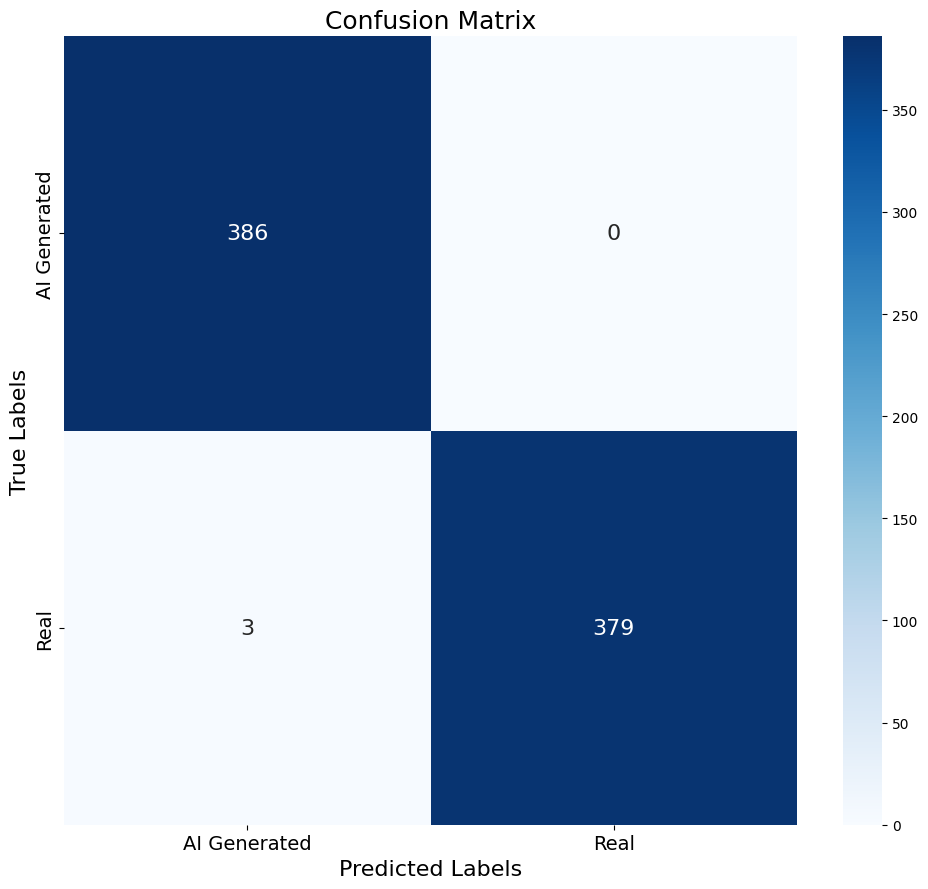

In [28]:
conf_matrix = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(10, 9))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 16}
)
plt.xlabel("Predicted Labels", fontsize=16)
plt.ylabel("True Labels", fontsize=16)
plt.title("Confusion Matrix", fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.savefig("Efficientnet CM.png", dpi = 600)
plt.show()


# Plotting the Accuracy and Loss Curves

In [26]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

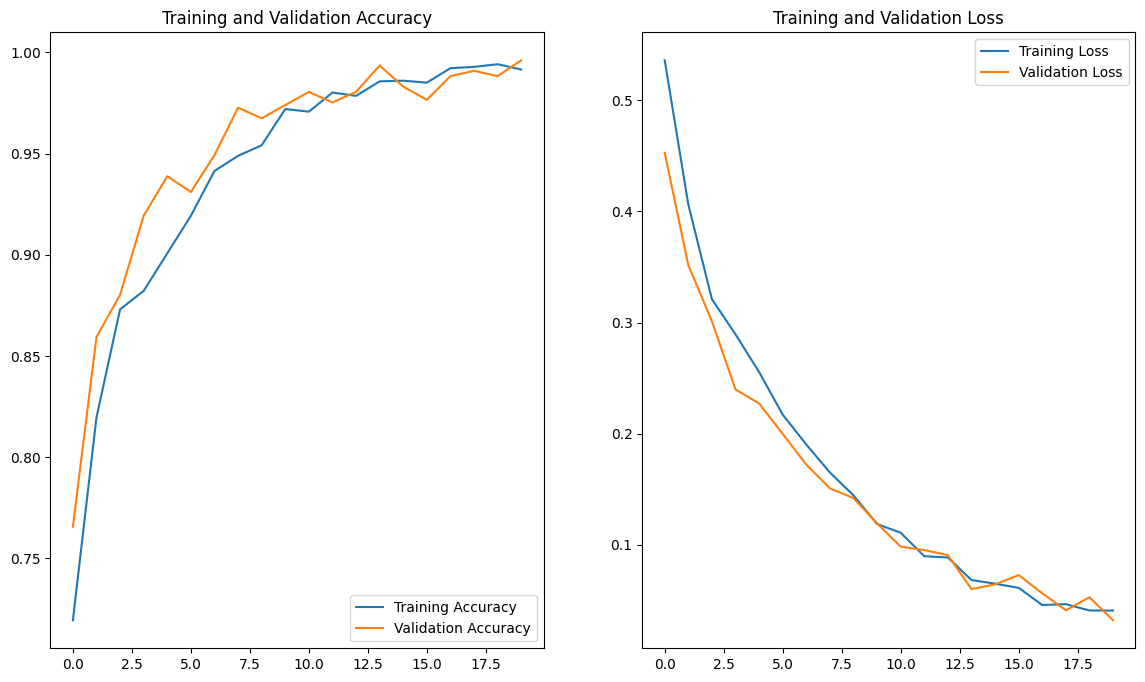

In [27]:
plt.figure(figsize=(14, 8))
plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label='Training Loss')
plt.plot(range(EPOCHS), val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

# Inference



## Inference Function

In [29]:
def predict(model, image):
    img_array = tf.keras.preprocessing.image.img_to_array(image.numpy())
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

## Running Inference on Sample Images

In [30]:
plt.clf()
plt.figure(figsize=(16, 10))
image_count = 0

for images, labels in test_ds.take(3):
    for i in range(min(8, len(images))):
        ax = plt.subplot(2, 4, i + 1)
        ax.imshow(images[i].numpy().astype("uint8"))

        predicted_class, confidence = predict(model, images[i])
        actual_class = class_names[labels[i]]

        ax.set_title(f"Actual: {actual_class}\nPred: {predicted_class}\nConf: {confidence:.2f}%")
        ax.axis("off")

plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.